In [1]:
import os 
import matplotlib

import numpy as np 
import pandas as pd 
import seaborn as sns 

import matplotlib.pyplot as plt 

matplotlib.rcParams.update({
    'font.family': 'STIXGeneral',
    'mathtext.fontset': 'stix',
})

In [2]:
data_path = '/home/ruppk2@hhmi.org/tracktail-paper/data/survival_curves_final.csv'
outpath = '/home/ruppk2@hhmi.org/tracktail-paper/figures/v1'
data = pd.read_csv(data_path)

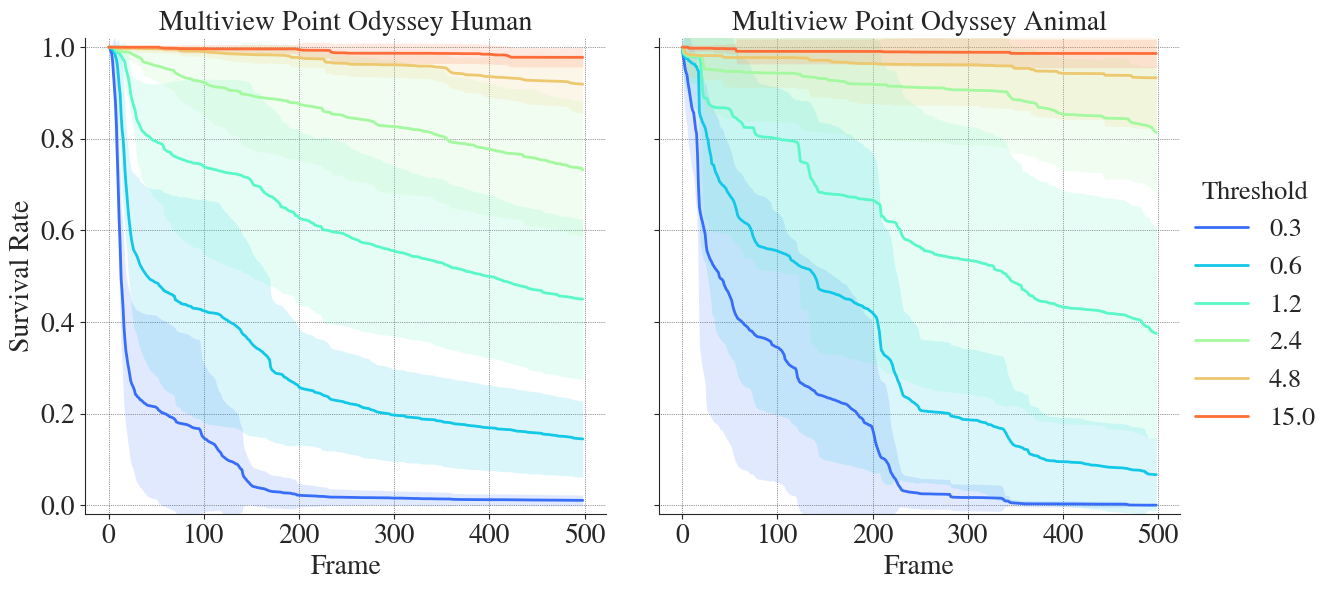

In [56]:
# tracktail survival on mv po for various thresholds 

# sns.set_style('ticks')
sns.set_style('ticks', {'font.family': 'STIXGeneral'})
fs = 20

fig, axs = plt.subplots(1, 2, figsize = (12, 6), sharey = True)
axs = axs.flatten()

palette = sns.color_palette('rainbow', n_colors = 6)
tracktail_df = data[data['model'] == 'posetail'] 
datasets = ['human', 'animal']

for i, (ax, dataset) in enumerate(zip(axs, datasets)): 

    sub_df = tracktail_df[tracktail_df['dataset'] == dataset]
    sns.lineplot(
        data = sub_df,
        x = 'frame',
        y = 'survival_mean',
        hue = 'threshold',
        # marker = 'o',
        linewidth = 2,
        markersize = 7,
        palette = palette,
        ax = ax,
    )

    for thr, color in zip(sub_df['threshold'].unique(), palette):
        thresh_df = sub_df[sub_df['threshold'] == thr].sort_values('frame')
        ax.fill_between(
            thresh_df['frame'],
            thresh_df['survival_mean'] - thresh_df['survival_std'],
            thresh_df['survival_mean'] + thresh_df['survival_std'],
            color = color,
            alpha = 0.15,
            linewidth = 0,
        )

    ax.set_xlabel('Frame', fontsize = fs)

    if i == 0:
        ax.set_ylabel('Survival Rate', fontsize = fs)
    else: 
        ax.set_ylabel('')
    
    # ax.set_title(f'{dataset.capitalize()}', fontsize = fs)
    ax.set_title(f'Multiview Point Odyssey {dataset.capitalize()}', fontsize = fs)
    ax.tick_params(axis = 'x', labelsize = fs)
    ax.tick_params(axis = 'y', labelsize = fs)
    ax.get_legend().remove()
    ax.grid(True, linestyle=':', color = 'k', linewidth=0.5, alpha=0.8)
    ax.set_ylim([-0.02, 1.02])

# single shared legend outside the subplots
handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, labels, 
           title = 'Threshold',
           title_fontsize = fs - 1,
           loc='upper center',
           bbox_to_anchor = (1.05, 0.73), 
           frameon = False, 
           fontsize = fs - 1)

plt.tight_layout()
plt.subplots_adjust(wspace = 0.1)
sns.despine() 

outdir = os.path.dirname(outpath)
if outdir:
    os.makedirs(outdir, exist_ok=True)
    
fig.savefig(os.path.join(outpath, 'po_survival_tracktail.pdf'), dpi=800, bbox_inches='tight')


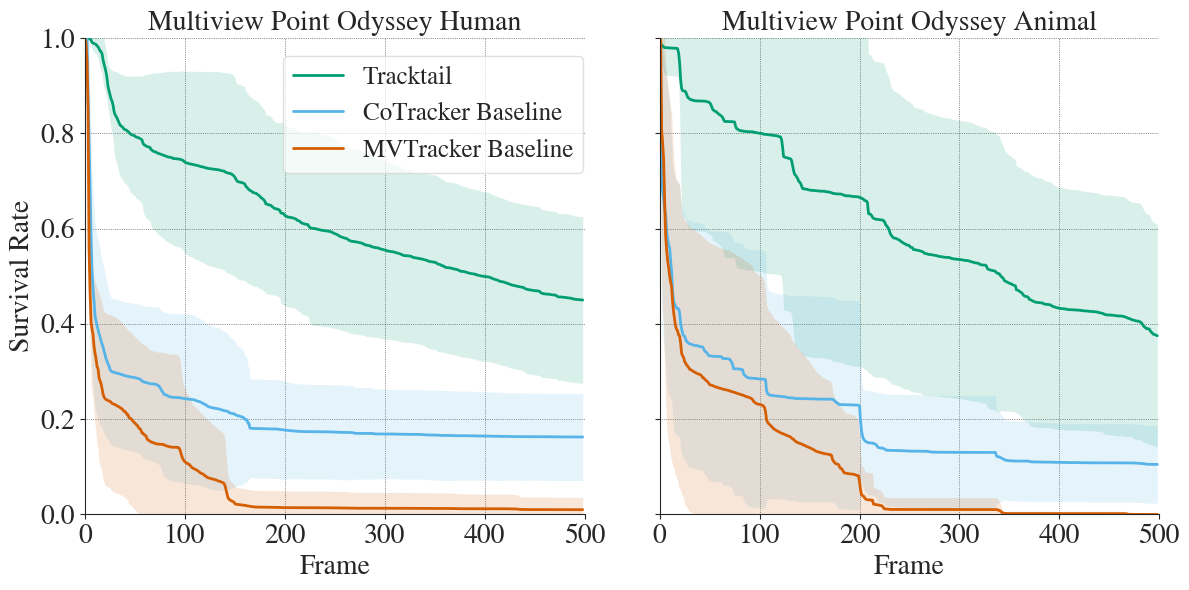

In [16]:
# surival rate comparison on mv po for various methods 

# label_dict = {
#     'posetail_human': 'Tracktail (Human)',
#     'posetail_animal': 'Tracktail (Animal)',
#     'cotracker_human': 'CoTracker Baseline (Human)',
#     'cotracker_animal': 'CoTracker Baseline (Animal)',
#     'mvtracker-4cams-duster_human': 'MVTracker Baseline (Human)',
#     'mvtracker-4cams-duster_animal': 'MVTracker Baseline (Animal)',
# }


label_dict = {
    'posetail': 'Tracktail',
    'cotracker': 'CoTracker Baseline',
    'mvtracker-4cams-duster': 'MVTracker Baseline',
}

# sns.set_style('ticks')
sns.set_style('ticks', {'font.family': 'STIXGeneral'})
fs = 20

fig, axs = plt.subplots(1, 2, figsize = (12, 6), sharey = True)
axs = axs.flatten()

palette = sns.color_palette('colorblind', n_colors = 12)
colors = [palette[2], palette[9], palette[3]]
# colors = [palette[4], palette[9], palette[3]]

thresh = 1.2 # [ 0.3,  0.6,  1.2,  2.4,  4.8, 15. ]
threshold_df = data[data['threshold'] == thresh] 
threshold_df = threshold_df[~threshold_df['model'].str.contains('-gt')]

# models = ['posetail', 'cotracker', 'mvtracker-4cams-duster']
# color_dict = {f'{m}_{d}': c
#               for m, c in zip(models, colors)
#               for d in ['human', 'animal']}
# dash_dict  = {k: (1, 0) if k.endswith('_human') else (4, 2)
#               for k in color_dict}

datasets = ['human', 'animal']

for i, (ax, dataset) in enumerate(zip(axs, datasets)): 

    dataset_df = threshold_df[threshold_df['dataset'] == dataset]
    sns.lineplot(
        data = dataset_df,
        x = 'frame',
        y = 'survival_mean',
        hue = 'model',
        # marker = 'o',
        linewidth = 2,
        markersize = 7,
        palette = colors,
        ax = ax,
    )

    for model, color in zip(dataset_df['model'].unique(), colors):
        sub = dataset_df[dataset_df['model'] == model].sort_values('frame')
        ax.fill_between(
            sub['frame'],
            sub['survival_mean'] - sub['survival_std'],
            sub['survival_mean'] + sub['survival_std'],
            color=color,
            alpha=0.15,
            linewidth=0,
        )

    every_n = 50 

    # for line in ax.lines:
    #     line.set_marker('o')
    #     line.set_markevery(every_n)
    #     line.set_markersize(8)

    # for model, color in zip(dataset_df['model'].unique(), colors):
    #     sub = dataset_df[dataset_df['model'] == model].sort_values('frame')
    #     sub_sampled = sub[sub['frame'] % every_n == 0]
    #     ax.errorbar(
    #         sub_sampled['frame'],
    #         sub_sampled['survival_mean'],
    #         yerr=sub_sampled['survival_std'],
    #         fmt='none',
    #         color=color,
    #         capsize=3,
    #         capthick=1.5,
    #         elinewidth=1.5,
    #     )


    ax.set_xlabel('Frame', fontsize = fs)

    if i == 0:
        ax.set_ylabel('Survival Rate', fontsize = fs)
    else: 
        ax.set_ylabel('')
        
    # ax.set_title(f'{dataset.capitalize()}', fontsize = fs)
    ax.set_title(f'Multiview Point Odyssey {dataset.capitalize()}', fontsize = fs)
    ax.tick_params(axis = 'x', labelsize = fs)
    ax.tick_params(axis = 'y', labelsize = fs)
    ax.get_legend().remove()
    ax.grid(True, linestyle=':', color = 'k', linewidth=0.5, alpha=0.8)
    ax.set_xlim([0, 500])
    ax.set_ylim([0, 1])

# single shared legend outside the subplots 
handles, labels = ax.get_legend_handles_labels()
labels = [label_dict[label] for label in labels]

seen = {}
for h, l in zip(handles, labels):
    if l not in seen:
        seen[l] = h
        
fig.legend(seen.values(), seen.keys(), 
        loc='upper center',
        bbox_to_anchor = (0.365, 0.92), 
        framealpha = 0.7, 
        facecolor = 'white', 
        edgecolor = 'lightgray',
        fontsize = fs - 2)

plt.tight_layout()
plt.subplots_adjust(wspace = 0.15)
sns.despine() 

outdir = os.path.dirname(outpath)
if outdir:
    os.makedirs(outdir, exist_ok=True)
    
fig.savefig(os.path.join(outpath, f'po_survival_comparison_{thresh}.pdf'), dpi=800, bbox_inches='tight')


In [ ]:
# # surival rate comparison on mv po for various methods 

# label_dict = {
#     'posetail_human': 'Tracktail (Human)',
#     'posetail_animal': 'Tracktail (Animal)',
#     'cotracker_human': 'CoTracker Baseline (Human)',
#     'cotracker_animal': 'CoTracker Baseline (Animal)',
#     'mvtracker-4cams-duster_human': 'MVTracker Baseline (Human)',
#     'mvtracker-4cams-duster_animal': 'MVTracker Baseline (Animal)',
# }

# # sns.set_style('ticks')
# sns.set_style('ticks', {'font.family': 'STIXGeneral'})
# fs = 20

# fig, axs = plt.subplots(1, 2, figsize = (6, 6), sharey = False)
# axs = axs.flatten()

# palette = sns.color_palette('rainbow', n_colors = 6)
# colors = [palette[0], palette[2], palette[4]]

# threshold_df = data[data['threshold'] == 2.4] # [ 0.3,  0.6,  1.2,  2.4,  4.8, 15. ]
# threshold_df = threshold_df[~threshold_df['model'].str.contains('-gt')]
# threshold_df['model_dataset'] = threshold_df['model'] + '_' + threshold_df['dataset']

# # models = ['posetail', 'cotracker', 'mvtracker-4cams-duster']
# # color_dict = {f'{m}_{d}': c
# #               for m, c in zip(models, colors)
# #               for d in ['human', 'animal']}
# # dash_dict  = {k: (1, 0) if k.endswith('_human') else (4, 2)
# #               for k in color_dict}

# datasets = ['human', 'animal']

# for ax, dataset in enumerate(ax, datasets): 

#     dataset_df = threshold_df[threshold_df['dataset'] == dataset]
#     sns.lineplot(
#         data = threshold_df,
#         x = 'frame',
#         y = 'survival_mean',
#         hue = 'model_dataset',
#         # marker = 'o',
#         linewidth = 2,
#         markersize = 7,
#         palette = color_dict,
#         ax = ax,
#     )



#     for thr, color in zip(sub_df['threshold'].unique(), palette):
#         thresh_df = sub_df[sub_df['threshold'] == thr].sort_values('frame')
#         ax.fill_between(
#             thresh_df['frame'],
#             thresh_df['survival_mean'] - thresh_df['survival_std'],
#             thresh_df['survival_mean'] + thresh_df['survival_std'],
#             color = color,
#             alpha = 0.15,
#             linewidth = 0,
#         )

# ax.set_xlabel('Frame', fontsize = fs)
# ax.set_ylabel('Survival Rate', fontsize = fs)
# # ax.set_title(f'{dataset.capitalize()}', fontsize = fs)
# # ax.set_title(f'Multiview Point Odyssey {dataset.capitalize()} Dataset', fontsize = fs)
# ax.tick_params(axis = 'x', labelsize = fs)
# ax.tick_params(axis = 'y', labelsize = fs)
# ax.get_legend().remove()
# ax.grid(True, linestyle=':', color = 'k', linewidth=0.5, alpha=0.8)
# ax.set_xlim([0, 500])

# # single shared legend outside the subplots
# handles, labels = ax.get_legend_handles_labels()
# labels = [label_dict[label] for label in labels]

# seen = {}
# for h, l in zip(handles, labels):
#     if l not in seen:
#         seen[l] = h
        
# fig.legend(seen.values(), seen.keys(), 
#            loc='upper center',
#            bbox_to_anchor = (1.3, 0.73), 
#            frameon = False, 
#            fontsize = fs - 1)

# plt.tight_layout()
# sns.despine() 

# outdir = os.path.dirname(outpath)
# if outdir:
#     os.makedirs(outdir, exist_ok=True)
    
# fig.savefig(os.path.join(outpath, 'po_survival_comparison.png'), dpi=800, bbox_inches='tight')
